# 3. Pré-processamento e data augmentation

← [Qualidade dos dados e limpeza](02_data_quality.ipynb) · [índice](README.pt-BR.md) · [Modelos](04_models.ipynb) →

Normalização por canal e data augmentation feita na GPU.

## Pré-processamento e *data augmentation*

**Normalização.** Subtraio a
média de cada canal de cor (3 números, como na VGGNet). Essas estatísticas vêm apenas do conjunto de
treino, para não vazar informação da validação nem do teste.

Em imagens, não é comum normalizar também pela variância. Mesmo assim, também divido
pelo desvio padrão de cada canal. Os três desvios são praticamente iguais (cerca de 0,20), então a divisão
não muda o peso relativo dos canais. Ela só reescala a entrada em cerca de 5 vezes e deixa a variância
perto de 1, que é o que a inicialização He supõe: ela escolhe a escala dos pesos
para que a variância das ativações se mantenha de uma camada para a outra. Isso pesa principalmente na MLP,
que não tem BatchNorm no baseline.

**Desempenho.** Como as imagens são pequenas, o conjunto inteiro (cerca de 220 MB em `uint8`) cabe direto na
GPU. A normalização e a augmentation rodam por batch na própria GPU, o que evita o gargalo do `DataLoader`.

**Data augmentation.** A técnica ficou conhecida com a AlexNet. Cada imagem recebe uma
transformação afim aleatória (rotação de até 10° para cada lado, translação de até 10% e escala entre 0,9 e
1,1) e uma variação de brilho e contraste de até 20%. Não uso flip horizontal, porque um dígito espelhado
deixa de ser o mesmo dígito.

In [1]:
import inspect
from IPython.display import Code, display

def show(*objs):
    """Mostra o código-fonte das funções/classes (definidas em svhn_utils.py)."""
    display(Code("\n\n".join(inspect.getsource(o) for o in objs), language="python"))

import matplotlib.pyplot as plt

from svhn_utils import figures_dir, Normalizer, augment, channel_stats, load_data, set_seed
FIG_DIR = figures_dir("03_preprocessing")   # figuras deste notebook em outputs/figures/03_preprocessing/

show(channel_stats, Normalizer, augment)

def channel_stats(X_uint8):
    Xf = X_uint8.float() / 255.0
    return Xf.mean(dim=(0, 2, 3)), Xf.std(dim=(0, 2, 3))


class Normalizer:
    def __init__(self, mean, std, device):
        self.mean = torch.as_tensor(mean, dtype=torch.float32).view(1, 3, 1, 1).to(device)
        self.std = torch.as_tensor(std, dtype=torch.float32).view(1, 3, 1, 1).to(device)

    def __call__(self, x_uint8):
        return (x_uint8.float() / 255.0 - self.mean) / self.std

    def state_dict(self):
        return {"mean": self.mean.flatten().cpu().tolist(), "std": self.std.flatten().cpu().tolist()}


def augment(x, max_rot=10.0, max_shift=0.1, scale=(0.9, 1.1), jitter=0.2):
    # x: float em [0,1], [B,3,H,W]; parâmetros aleatórios independentes por imagem
    B, dev = x.shape[0], x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(max_rot)
    s = torch.empty(B, device=dev).uniform_(*scale)
    tx = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2   # coordenadas normalizadas [-1,1]
    ty = (torch.rand(B, device=dev) * 2 - 1) * max_shift * 2
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
    brightness = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * jitter
    contrast = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * jitter
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return (((x - m) * contrast + m) * brightness).clamp(0, 1)

média por canal: [0.4376 0.4437 0.4728] | desvio: [0.1979 0.2009 0.1969]


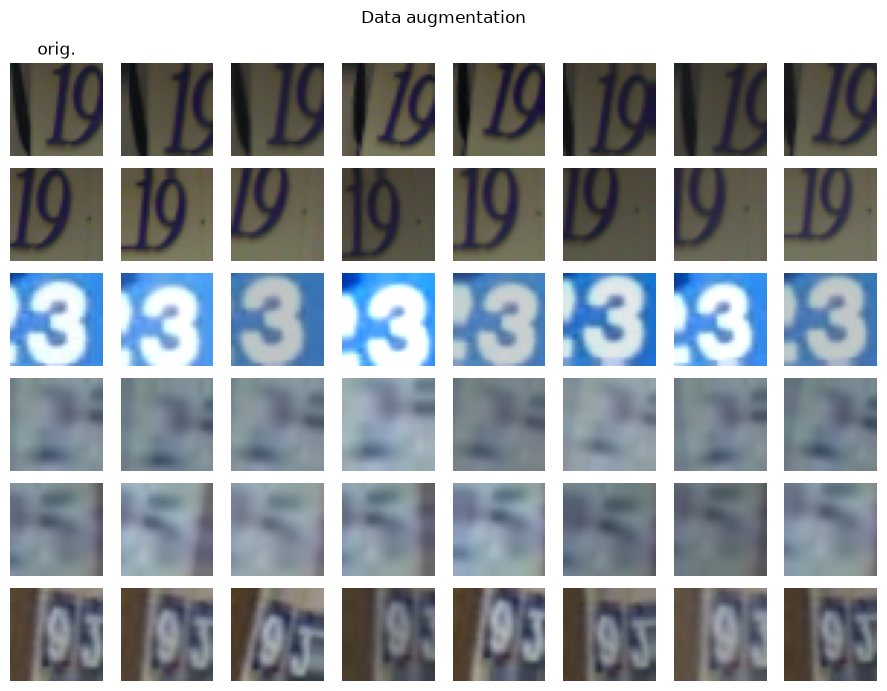

In [2]:
data, _ = load_data()
mean, std = channel_stats(data["train"][0])
print("média por canal:", mean.numpy().round(4), "| desvio:", std.numpy().round(4))

# visualização: original (1ª coluna) e 7 versões aumentadas
set_seed(0)
sample = data["train"][0][:6].float() / 255.0
fig, axes = plt.subplots(6, 8, figsize=(9, 7))
for r in range(6):
    axes[r, 0].imshow(sample[r].permute(1, 2, 0)); axes[r, 0].set_title("orig." if r == 0 else "")
    for c in range(1, 8):
        axes[r, c].imshow(augment(sample[r:r+1])[0].permute(1, 2, 0))
for ax in axes.flat: ax.axis("off")
plt.suptitle("Data augmentation"); plt.tight_layout()
plt.savefig(FIG_DIR / "augmentation.png", dpi=150); plt.show()